# CIFAR-10: exploring, clustering and classifying
Loading the data and picking the training, validation and test samples used in every part.

In [1]:
import platform
import random
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
import torchvision
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support, silhouette_score)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from torch import nn
from torchvision import datasets
from torchvision.models import ResNet18_Weights, resnet18
from torchvision.transforms import v2

In [2]:
SEED = 32

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
# numpy's random numbers can change between versions, so print them
print(f"python {platform.python_version()}, numpy {np.__version__}, "
      f"torch {torch.__version__}, torchvision {torchvision.__version__}")
print(f"seed {SEED}, device {device}")

python 3.13.3, numpy 2.5.5, torch 2.15.0, torchvision 0.29.2
seed 32, device mps


In [3]:
train_set = datasets.CIFAR10("data", train=True, download=True)
test_set = datasets.CIFAR10("data", train=False, download=True)

train_images, train_labels = train_set.data, np.array(train_set.targets)
test_images, test_labels = test_set.data, np.array(test_set.targets)
classes = train_set.classes
print(train_images.shape, test_images.shape)

(50000, 32, 32, 3) (10000, 32, 32, 3)


In [4]:
sns.set_theme(style="white", context="paper")
# font sizes set once so all figures match in the report
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight",
                     "image.interpolation": "nearest", "font.size": 6.5,
                     "axes.titlesize": 7, "axes.labelsize": 6.5, "xtick.labelsize": 6,
                     "ytick.labelsize": 6, "legend.fontsize": 6, "figure.titlesize": 7.5,
                     "axes.titlepad": 2})
TEXT_WIDTH = 6.85  # page width in inches
class_colours = dict(zip(classes, sns.color_palette("tab10", len(classes))))
short_names = ["plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

## Samples
Each class is shuffled once with the seed. 500 training and 50 validation images per class come from the training set, and 50 test images per class from the test set.

In [5]:
rng = np.random.default_rng(SEED)

def sample_per_class(labels, sizes):
    # shuffle each class once and slice it, so the samples never overlap
    samples = [[] for _ in sizes]
    for c in range(len(classes)):
        idx = rng.permutation(np.flatnonzero(labels == c))
        start = 0
        for sample, n in zip(samples, sizes):
            sample.append(idx[start:start + n])
            start += n
    return [np.sort(np.concatenate(s)) for s in samples]

train_idx, val_idx = sample_per_class(train_labels, [500, 50])
(test_idx,) = sample_per_class(test_labels, [50])

for name, idx, labels in [("train", train_idx, train_labels),
                          ("val", val_idx, train_labels),
                          ("test", test_idx, test_labels)]:
    print(name, len(idx), np.bincount(labels[idx]))
print("train and val overlap:", len(np.intersect1d(train_idx, val_idx)))

train 5000 [500 500 500 500 500 500 500 500 500 500]
val 500 [50 50 50 50 50 50 50 50 50 50]
test 500 [50 50 50 50 50 50 50 50 50 50]
train and val overlap: 0


## Part A

## A1
How many images each set has, and the average and spread of each colour. Then one example image per class.

In [6]:
set_labels = {"train full": train_labels, "test full": test_labels,
              "train sample": train_labels[train_idx], "val sample": train_labels[val_idx],
              "test sample": test_labels[test_idx]}
set_counts = pd.DataFrame({"images": [len(y) for y in set_labels.values()],
                           "min per class": [np.bincount(y).min() for y in set_labels.values()],
                           "max per class": [np.bincount(y).max() for y in set_labels.values()]},
                          index=set_labels)
print(set_counts)

              images  min per class  max per class
train full     50000           5000           5000
test full      10000           1000           1000
train sample    5000            500            500
val sample       500             50             50
test sample      500             50             50


In [7]:
def channel_stats(images):
    pixels = images.reshape(-1, 3)
    # one colour at a time to save memory
    std = np.array([pixels[:, ch].std() for ch in range(3)])
    return pixels.mean(axis=0) / 255, std / 255

# worked out again in A3 after cleaning
channel_mean, channel_std = channel_stats(train_images[train_idx])
full_mean, full_std = channel_stats(train_images)

print(f"pixels {train_images.dtype}, range {train_images.min()} to {train_images.max()}")
print(pd.DataFrame({"sample mean": channel_mean, "sample std": channel_std,
                    "full mean": full_mean, "full std": full_std},
                   index=["red", "green", "blue"]).round(3))
print(f"largest sample-to-full gap {max(np.abs(channel_mean - full_mean).max(), np.abs(channel_std - full_std).max()):.3f}")

pixels uint8, range 0 to 255
       sample mean  sample std  full mean  full std
red          0.491       0.247      0.491     0.247
green        0.482       0.243      0.482     0.243
blue         0.445       0.261      0.447     0.262
largest sample-to-full gap 0.002


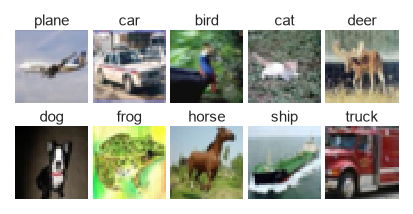

In [8]:
first_per_class = [train_idx[train_labels[train_idx] == c][0] for c in range(len(classes))]

fig, axes = plt.subplots(2, 5, figsize=(3.3, 1.5), gridspec_kw={"wspace": 0.06, "hspace": 0.25})
for ax, i, name in zip(axes.flat, first_per_class, short_names):
    ax.imshow(train_images[i])
    ax.set_title(name)
    ax.axis("off")
fig.savefig("figures/a1_examples.png")
plt.show()